<a href="https://colab.research.google.com/github/mvaishnavi2007/ITA0520---CV/blob/main/EXP_15_HARRIS_CORNER_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
uploaded = files.upload()

Saving Screenshot 2026-11-11 110658.png to Screenshot 2026-11-11 110658 (1).png


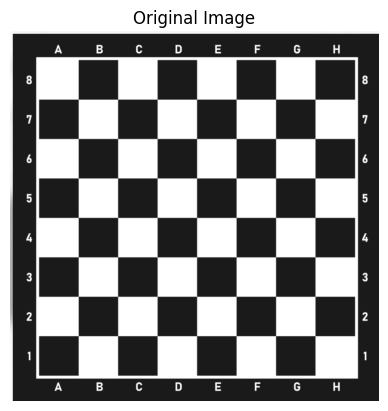

In [4]:
filename = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_COLOR
)

if img is None:
    raise ValueError("Please upload a valid image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gray = np.float32(gray)

print("Gray-scale conversion completed")

Gray-scale conversion completed


In [6]:
dst = cv2.cornerHarris(
    gray,
    2,
    3,
    0.04
)

dst = cv2.dilate(dst, None)

print("Harris corner detection completed")

Harris corner detection completed


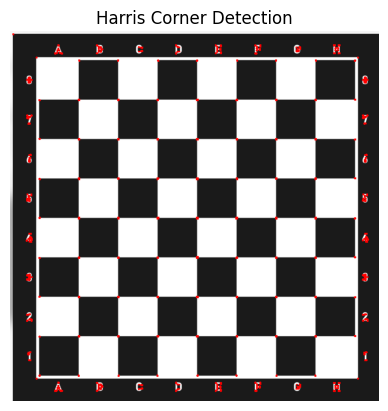

In [7]:
result = img.copy()

threshold = 0.01 * dst.max()

result[dst > threshold] = [0, 0, 255]

result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.imshow(result_rgb)
plt.title("Harris Corner Detection")
plt.axis("off")
plt.show()

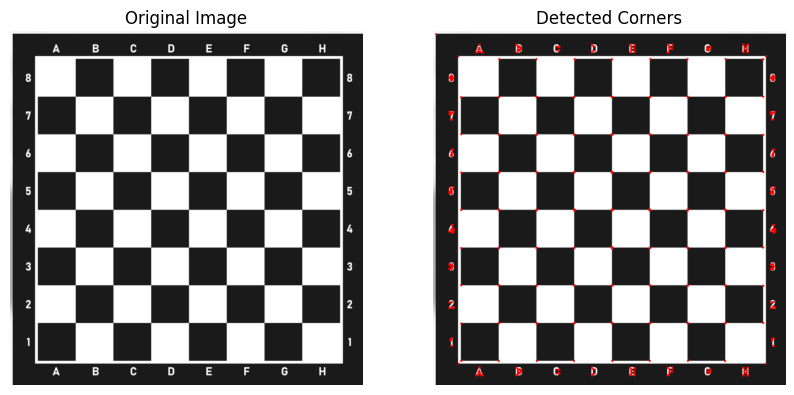

In [8]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title("Detected Corners")
plt.axis("off")

plt.show()

In [10]:
cv2.imwrite("harris_corners.jpg", result)
files.download("harris_corners.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>